In [ ]:
import os, sys
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R'
import numpy as np
import pandas as pd
import scanpy as sc
import scFates as scf
import scipy.sparse as sp
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
np.random.seed(0)

In [ ]:
name = os.path.basename(os.getcwd())
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Head-and-Neck', name)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
adata

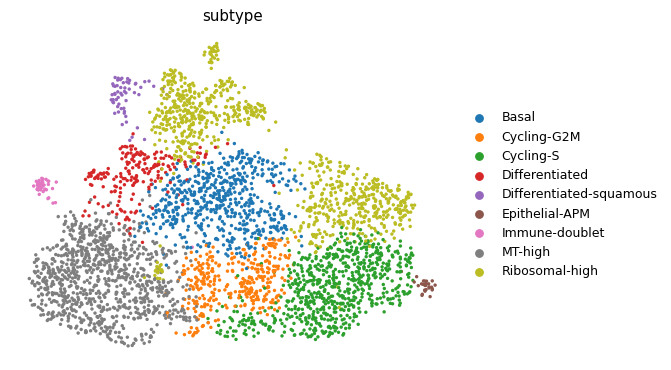

In [ ]:
sc.pl.umap(adata, color = 'subtype', size = 30, frameon = False)

In [ ]:
# Score the three embryonic-development modules on malignant cells. gene_pool =
# union.csv control pool; ctrl_size matched to each set. Smoothed copies (suffix
# _s) average each score over the kNN graph for a de-noised geography read.
fd = os.path.join(pth, 'data', 'features', 'biomart')
_load = lambda f: pd.read_csv(os.path.join(fd, f))['hsapiens'].dropna().drop_duplicates().tolist()
sets = {'Gast':_load('GSE162534.csv'), 'pSom':_load('GSE229103.csv'), 'Crest':_load('rRNAModifications.csv')}
pool = [g for g in _load('union.csv') if g in adata.var_names]
for k, g in sets.items():
    gg = [x for x in g if x in adata.var_names]
    sc.tl.score_genes(adata, gg, score_name = k, gene_pool = pool, ctrl_size = len(gg), random_state = 0)
C = adata.obsp['connectivities'] + sp.eye(adata.n_obs)
Cn = sp.diags(1 / np.asarray(C.sum(1)).ravel()) @ C
for k in sets:
    adata.obs[k + '_s'] = Cn @ adata.obs[k].values
print(adata.obs[['Gast','pSom','Crest']].corr().round(3).to_string())

        Gast   pSom  Crest
Gast   1.000 -0.048 -0.541
pSom  -0.048  1.000 -0.438
Crest -0.541 -0.438  1.000


In [ ]:
# TOPOLOGY DECISION (Gate 2 biology drives geometry, not the reverse).
# Diagnostic evidence on this dataset:
#   - Gast & pSom CO-VARY across the manifold (per-node-cluster corr = +0.16),
#     and both peak together at the Gast/pSom-high progenitor -> they OVERLAP,
#     they do NOT cross-repress into two competing arms.
#   - Crest is the INVERSE / terminal gradient: anti-correlated with both Gast
#     (-0.65) and pSom (-0.39).
#   - A PPT tree's two 'arms' separated along Gast/Crest (not Gast-vs-pSom), i.e.
#     the tree imposed a fork on what is a single (Gast/pSom)->Crest axis.
#   - No proliferation confound: Gast anti-correlates with cell-cycle score, so
#     the Gast-high progenitor is quiescent, not a cycling artifact.
# => NON-BRANCHING case (spec): fit a principal CURVE, root at the Gast/pSom-high
#    (Crest-low) end. Gate 3 (cross-repression) is therefore N/A.
scf.tl.curve(adata, Nodes = 10, use_rep = 'X_umap', seed = 1)
B = adata.uns['graph']['B']; deg = np.asarray(B.sum(1)).ravel()
tips = np.where(deg == 1)[0]
print('n tips:', len(tips), 'tip nodes:', tips.tolist())

inferring a principal curve --> parameters used 
    10 principal points, mu = 0.1, lambda = 0.01
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
n tips: 2 tip nodes: [0, 2]


In [ ]:
# Root by DEVELOPMENTAL ORDER: the earliest state is the Gast/pSom-high,
# Crest-low progenitor. Pick the curve tip whose cell-neighbourhood has the
# highest Gast_s + pSom_s.
R = np.asarray(adata.obsm['X_R']); cell_node = R.argmax(1)
def tip_sig(n):
    m = adata.obs.loc[cell_node == n]
    return m['Gast_s'].mean() + m['pSom_s'].mean()
root = int(max(tips, key = tip_sig))
for n in tips:
    m = adata.obs.loc[cell_node == n]
    print(f'tip {n}: Gast_s={m.Gast_s.mean():+.4f} pSom_s={m.pSom_s.mean():+.4f} Crest_s={m.Crest_s.mean():+.4f}')
print('root tip =', root)
scf.tl.root(adata, root)

tip 0: Gast_s=-0.0055 pSom_s=+0.0010 Crest_s=-0.0123
tip 2: Gast_s=-0.0229 pSom_s=-0.0066 Crest_s=+0.0044
root tip = 0
node 0 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.


In [ ]:
scf.tl.pseudotime(adata, n_jobs = 4, seed = 0)
# Along pseudotime from the progenitor: Gast/pSom should FALL, Crest should RISE.
for c in ['Gast_s', 'pSom_s', 'Crest_s']:
    print(f'corr(t, {c}) = {np.corrcoef(adata.obs.t, adata.obs[c])[0,1]:+.3f}')

projecting cells onto the principal graph
    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
corr(t, Gast_s) = -0.579
corr(t, pSom_s) = -0.106
corr(t, Crest_s) = +0.443


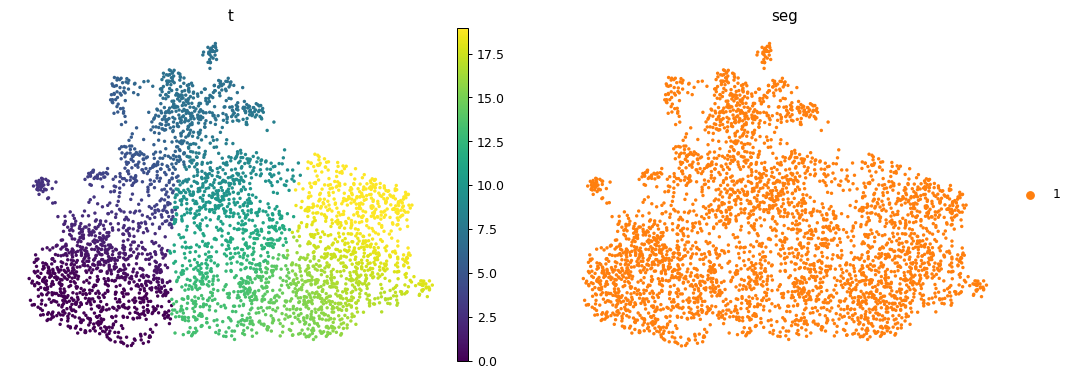

In [ ]:
sc.pl.umap(adata, color = ['t', 'seg'], size = 30, frameon = False)

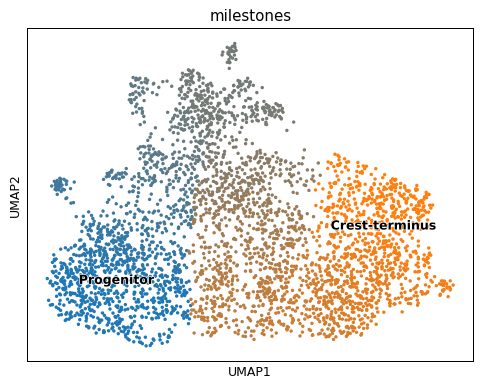

In [ ]:
# A curve has two milestones: the rooted Gast/pSom-high Progenitor and the
# Crest-high Terminus. Name them by pseudotemporal role.
ms = adata.obs['milestones'].cat.categories.tolist()
t_by_ms = adata.obs.groupby('milestones', observed=True)['t'].mean()
prog = t_by_ms.idxmin(); term = t_by_ms.idxmax()
scf.tl.rename_milestones(adata, new = {prog:'Progenitor', term:'Crest-terminus'})
scf.pl.milestones(adata, basis = 'umap', annotate = True, s = 30)

In [ ]:
adata.uns['topology'] = {'geometry':'curve', 'branching':False,
    'root_tip':int(root), 'Nodes':10,
    'corr_t_Gast':float(np.corrcoef(adata.obs.t, adata.obs.Gast_s)[0,1]),
    'corr_t_pSom':float(np.corrcoef(adata.obs.t, adata.obs.pSom_s)[0,1]),
    'corr_t_Crest':float(np.corrcoef(adata.obs.t, adata.obs.Crest_s)[0,1]),
    'gate3':'NA (non-branching)'}
# elpigraph stores its raw fit as a dict of ragged arrays in .uns['epg'];
# it is not needed downstream (graph/pp_info/t/seg carry the trajectory) and
# breaks h5ad serialization -> drop it before writing.
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (3674, 22080)


saved manifold.pdf


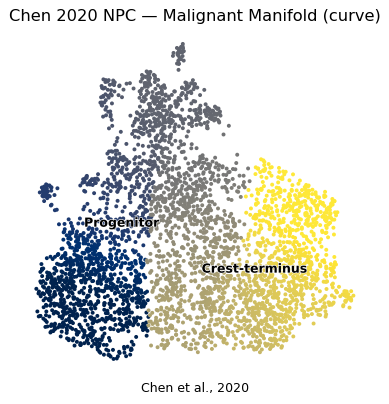

In [ ]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 't', cmap = 'cividis', size = 40, colorbar_loc = None,
           frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 40, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.set_title('Chen 2020 NPC — Malignant Manifold (curve)', size = 13)
ax.text(.5, -.05, 'Chen et al., 2020', ha = 'center', transform = ax.transAxes)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches = 'tight')
print('saved manifold.pdf')